# Lecture 4: Tractor Tracks, Sentinel-2 Index Mosaics & MML 2 m Elevation (STAC)

This Google Colab notebook demonstrates how to:
1. Use the **Field Observatory** field block geometries (`mu_0` and `mu_1` at Mustiala) directly in Python.
2. Generate plausible timestamped **tractor tracks** working across both fields on two summer 2025 days (June 15 and August 15, 2025).
3. Perform **network-friendly windowed reads** (HTTP range requests via GDAL `/vsicurl/` and `rasterio`) from FMI's STAC catalogs:
   - **Sentinel-2 Index Mosaics** (`Sentinel-2_indeksimosaiikit.json`) for vegetation and moisture indices (`NDVI`, `NDMI`, `NDTI`) along the tracks.
   - **MML 2 m Digital Terrain Model** (`MML-DTM-2m.json`) for the elevation profile (`height`, meters N2000) along the tracks.
4. Plot the field tracks and the resulting timestamped time series.

In [15]:
# Install rasterio if not already present (e.g. in Google Colab)
!pip install -q rasterio

In [16]:
import json
import textwrap
import urllib.request
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import rasterio
from rasterio.transform import rowcol
from rasterio.windows import bounds as window_bounds, from_bounds
from shapely.affinity import rotate
from shapely.geometry import LineString, MultiLineString, shape
from shapely.ops import transform as shapely_transform

## 1. Field Block Geometries (`mu_0` and `mu_1`)

These two Mustiala field block polygons (WGS 84, `EPSG:4326`) are copied from `fieldobs_blocks_translated.geojson`.

In [17]:
FIELD_BLOCKS = {
    "mu_0": {
        "name": "Control plot (multi-species ley)",
        "altitude_m": 112.93,
        "geometry": {
            "type": "Polygon",
            "coordinates": [[
                [23.7842204, 60.823695099999995],
                [23.781218599999995, 60.824419199999994],
                [23.781703199999995, 60.82501130000001],
                [23.7841261, 60.824502300000006],
                [23.784221399999996, 60.824061099999994],
                [23.7842204, 60.823695099999995],
            ]],
        },
    },
    "mu_1": {
        "name": "Carbon farming plot (multi-species ley)",
        "altitude_m": 113.54,
        "geometry": {
            "type": "Polygon",
            "coordinates": [[
                [23.779311899999996, 60.82379890000001],
                [23.780650400000003, 60.82423180000001],
                [23.7825176, 60.82373119999998],
                [23.781694299999998, 60.8232666],
                [23.7807411, 60.823316399999996],
                [23.779311899999996, 60.82379890000001],
            ]],
        },
    },
}

to_tm35 = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:3067", always_xy=True).transform
to_wgs84 = pyproj.Transformer.from_crs("EPSG:3067", "EPSG:4326", always_xy=True).transform

polygons_wgs84 = {fid: shape(info["geometry"]) for fid, info in FIELD_BLOCKS.items()}
polygons_tm35 = {fid: shapely_transform(to_tm35, poly) for fid, poly in polygons_wgs84.items()}

for fid, poly in polygons_tm35.items():
    print(f"{fid}: {FIELD_BLOCKS[fid]['name']}, area = {poly.area / 10000:.2f} ha")

mu_0: Control plot (multi-species ley), area = 1.23 ha
mu_1: Carbon farming plot (multi-species ley), area = 1.03 ha


/tmp/ipykernel_1173/1170105754.py:38: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygons_tm35 = {fid: shapely_transform(to_tm35, poly) for fid, poly in polygons_wgs84.items()}


## 2. Generate Plausible Timestamped Tractor Tracks (Summer 2025)

We simulate back-and-forth parallel passes (12 m swath width, 5 m point spacing, 8 km/h driving speed) inside `mu_0` and `mu_1` on two dates in summer 2025:
- **2025-06-15** (early summer fieldwork)
- **2025-08-15** (late summer fieldwork)

In [18]:
def generate_field_track(poly_tm35, field_id, start_time, swath_width_m=12.0, step_m=5.0, speed_ms=2.22):
    """Generate alternating parallel tractor passes clipped inside a field polygon (EPSG:3067)."""
    # Align passes with the polygon's longest bounding-box edge
    coords = list(poly_tm35.minimum_rotated_rectangle.exterior.coords)
    edge1 = np.array(coords[1]) - np.array(coords[0])
    edge2 = np.array(coords[2]) - np.array(coords[1])
    main_vec = edge1 if np.linalg.norm(edge1) >= np.linalg.norm(edge2) else edge2
    angle_deg = np.degrees(np.arctan2(main_vec[1], main_vec[0]))

    origin = poly_tm35.centroid
    poly_rot = rotate(poly_tm35, -angle_deg, origin=origin).buffer(-3.0)
    minx, miny, maxx, maxy = poly_rot.bounds

    rows = []
    t_cur = start_time
    prev_pt = None
    y_vals = np.arange(miny + swath_width_m / 2, maxy, swath_width_m)

    for pass_idx, y in enumerate(y_vals):
        line = LineString([(minx - 10, y), (maxx + 10, y)]).intersection(poly_rot)
        if line.is_empty:
            continue
        segments = list(line.geoms) if isinstance(line, MultiLineString) else [line]
        segments.sort(key=lambda s: s.bounds[0], reverse=(pass_idx % 2 == 1))

        for seg in segments:
            n_pts = max(2, int(np.ceil(seg.length / step_m)) + 1)
            distances = np.linspace(0, seg.length, n_pts)
            if pass_idx % 2 == 1:
                distances = distances[::-1]
            for d in distances:
                pt_tm35 = rotate(seg.interpolate(d), angle_deg, origin=origin)
                if prev_pt is not None:
                    dist_m = pt_tm35.distance(prev_pt)
                    t_cur += timedelta(seconds=dist_m / speed_ms)
                lon, lat = to_wgs84(pt_tm35.x, pt_tm35.y)
                rows.append({
                    "timestamp_utc": t_cur,
                    "field_id": field_id,
                    "pass_num": pass_idx + 1,
                    "x_tm35": pt_tm35.x,
                    "y_tm35": pt_tm35.y,
                    "lon": lon,
                    "lat": lat,
                })
                prev_pt = pt_tm35

    return pd.DataFrame(rows), t_cur


WORK_DATES = [
    ("2025-06-15", "2025-06", datetime(2025, 6, 15, 8, 0, 0, tzinfo=timezone.utc)),
    ("2025-08-15", "2025-08", datetime(2025, 8, 15, 8, 0, 0, tzinfo=timezone.utc)),
]

all_tracks = []
for work_day, stac_month, day_start in WORK_DATES:
    df_mu0, t_end_0 = generate_field_track(polygons_tm35["mu_0"], "mu_0", day_start)
    # 5-minute road/headland transfer to mu_1
    df_mu1, _ = generate_field_track(polygons_tm35["mu_1"], "mu_1", t_end_0 + timedelta(minutes=5))
    df_day = pd.concat([df_mu0, df_mu1], ignore_index=True)
    df_day["work_day"] = work_day
    df_day["stac_month"] = stac_month
    all_tracks.append(df_day)

df_tracks = pd.concat(all_tracks, ignore_index=True)
print(f"Generated {len(df_tracks)} track points across {df_tracks['work_day'].nunique()} days.")
display(df_tracks.groupby(["work_day", "field_id"])["timestamp_utc"].agg(["count", "min", "max"]))

Generated 728 track points across 2 days.


count                              min  \
work_day   field_id                                           
2025-06-15 mu_0        194        2025-06-15 08:00:00+00:00   
           mu_1        170 2025-06-15 08:12:31.183791+00:00   
2025-08-15 mu_0        194        2025-08-15 08:00:00+00:00   
           mu_1        170 2025-08-15 08:12:31.183791+00:00   

                                                 max  
work_day   field_id                                   
2025-06-15 mu_0     2025-06-15 08:07:31.183791+00:00  
           mu_1     2025-06-15 08:19:12.071763+00:00  
2025-08-15 mu_0     2025-08-15 08:07:31.183791+00:00  
           mu_1     2025-08-15 08:19:12.071763+00:00

## 3. Network-Friendly STAC Reads (Sentinel-2 Index Mosaics & MML 2 m DTM)

Both datasets are served as Cloud-Optimized GeoTIFFs (COGs) or GDAL VRTs referenced by STAC catalogs. Using `rasterio` with `/vsicurl/` and `rasterio.windows.from_bounds(...)`, we fetch **only the small raster window** covering `mu_0` and `mu_1` via HTTP range requests rather than downloading full-country rasters.

### Satellite Index Explainers
- **NDVI (Normalized Difference Vegetation Index)**: Measures green vegetation density and vigor `(NIR - Red) / (NIR + Red)`. Higher values indicate denser, greener biomass (useful for estimating harvestable crop/grass yield before mowing).
- **NDMI (Normalized Difference Moisture Index)**: Measures vegetation canopy water content `(NIR - SWIR1) / (NIR + SWIR1)`. Higher values indicate moister vegetation (useful for assessing forage/silage moisture and drying conditions).
- **NDTI (Normalized Difference Tillage Index)**: Measures crop residue / stubble cover vs. bare soil `(SWIR1 - SWIR2) / (SWIR1 + SWIR2)`. Sensitive to harvest and tillage operations.
- **NDSI (Normalized Difference Snow Index)**: Measures snow cover vs. snow-free land `(Green - SWIR1) / (Green + SWIR1)`. Higher/positive values indicate snow cover, useful for winter or early-spring tractor operations.

### Mosaic Period Selection
By default (`PERIOD_SELECTION_MODE = "closest_end"`), we select the Tuulituhohaukka Sentinel-2 mosaic period whose **end date** is closest to the tractor work date — this reflects the vegetation conditions leading up to the work (e.g., harvesting). Set `PERIOD_SELECTION_MODE = "full_month"` to use the calendar-month mosaic instead.

In [19]:
S2_COLLECTION_URL = "https://pta.data.lit.fmi.fi/stac/catalog/Sentinel-2_indeksimosaiikit/Sentinel-2_indeksimosaiikit.json"
DTM_COLLECTION_URL = "https://pta.data.lit.fmi.fi/stac/catalog/MML-DTM-2m/MML-DTM-2m.json"


def fetch_json(url):
    with urllib.request.urlopen(url, timeout=30) as resp:
        return json.loads(resp.read().decode("utf-8"))


def vsicurl_href(href):
    return href if href.startswith("/vsicurl/") else f"/vsicurl/{href}"


def read_windowed_raster(href, xs_tm35, ys_tm35, buffer_m=50.0):
    """
    Read only the bounding-box window around (xs_tm35, ys_tm35) from a COG/VRT.
    Returns (vals_2d, extent_tm35, win_transform, xs_proj, ys_proj).
    """
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.vrt"):
        with rasterio.open(vsicurl_href(href)) as src:
            if src.crs and src.crs.to_epsg() != 3067:
                tr = pyproj.Transformer.from_crs("EPSG:3067", src.crs, always_xy=True)
                xs, ys = tr.transform(xs_tm35, ys_tm35)
            else:
                xs, ys = np.asarray(xs_tm35), np.asarray(ys_tm35)

            win = from_bounds(
                xs.min() - buffer_m,
                ys.min() - buffer_m,
                xs.max() + buffer_m,
                ys.max() + buffer_m,
                transform=src.transform,
            ).round_offsets().round_lengths()

            data = src.read(1, window=win, masked=True).astype("float64").filled(np.nan)
            win_transform = src.window_transform(win)
            left, bottom, right, top = window_bounds(win, src.transform)
            if src.crs and src.crs.to_epsg() != 3067:
                tr_back = pyproj.Transformer.from_crs(src.crs, "EPSG:3067", always_xy=True)
                left, bottom = tr_back.transform(left, bottom)
                right, top = tr_back.transform(right, top)
            extent_tm35 = [left, right, bottom, top]

            # Apply GeoTIFF scale/offset if defined; Sentinel-2 index mosaics store uint8 DN = 100 * index + 100
            scale = src.scales[0] if src.scales else 1.0
            offset = src.offsets[0] if src.offsets else 0.0
            if scale != 1.0 or offset != 0.0:
                data = data * scale + offset
            elif src.dtypes[0] == "uint8":
                data = (data - 100.0) / 100.0

            return data, extent_tm35, win_transform, xs, ys


def sample_from_raster(data_2d, win_transform, xs, ys):
    rows, cols = rowcol(win_transform, xs, ys)
    rows = np.clip(np.asarray(rows), 0, data_2d.shape[0] - 1)
    cols = np.clip(np.asarray(cols), 0, data_2d.shape[1] - 1)
    return data_2d[rows, cols]


# 1. Read MML 2 m DTM height window and sample along all track points
dtm_col = fetch_json(DTM_COLLECTION_URL)
dtm_child_url = next(lk["href"] for lk in dtm_col["links"] if lk.get("rel") == "child")
dtm_child = fetch_json(dtm_child_url)
dtm_item_url = next(lk["href"] for lk in dtm_child["links"] if lk.get("rel") == "item")
dtm_item = fetch_json(dtm_item_url)
dtm_height_href = dtm_item["assets"]["height"]["href"]

dtm_raster, dtm_extent, dtm_tf, dtm_xs, dtm_ys = read_windowed_raster(
    dtm_height_href, df_tracks["x_tm35"].values, df_tracks["y_tm35"].values
)
df_tracks["elevation_m"] = sample_from_raster(dtm_raster, dtm_tf, dtm_xs, dtm_ys)
print(f"Sampled MML 2 m DTM height (window {dtm_raster.shape} px): {dtm_height_href}")

# 2. Collect Tuulituhohaukka Sentinel-2 index mosaic periods (summer 2025) & sample track months
s2_col = fetch_json(S2_COLLECTION_URL)
s2_child_links = {lk["href"].split("_")[-1].replace(".json", ""): lk["href"] for lk in s2_col["links"] if lk.get("rel") == "child"}

SUMMER_MONTHS = ["2025-05", "2025-06", "2025-07", "2025-08", "2025-09"]
s2_periods = []
seen_items = set()
for m in SUMMER_MONTHS:
    if m not in s2_child_links:
        continue
    m_cat = fetch_json(s2_child_links[m])
    for lk in m_cat["links"]:
        if lk.get("rel") == "item" and lk["href"] not in seen_items:
            seen_items.add(lk["href"])
            item_meta = fetch_json(lk["href"])
            s2_periods.append({
                "id": item_meta["id"],
                "href": lk["href"],
                "start": pd.to_datetime(item_meta["properties"]["start_datetime"], utc=True),
                "end": pd.to_datetime(item_meta["properties"]["end_datetime"], utc=True),
                "item": item_meta,
            })
df_s2_periods = pd.DataFrame(s2_periods).sort_values("start").reset_index(drop=True)

PERIOD_SELECTION_MODE = "closest_end"  # "closest_end" (default) or "full_month"

INDEX_BANDS = ["ndvi", "ndmi", "ndti", "ndsi"]
for band in INDEX_BANDS:
    df_tracks[band] = np.nan

s2_rasters = {}
selected_periods = {}
for work_day, stac_month, day_dt in WORK_DATES:
    if PERIOD_SELECTION_MODE == "closest_end":
        # Pick the period whose end_datetime is closest to the tractor work date
        closest_idx = (df_s2_periods["end"] - pd.Timestamp(day_dt)).abs().idxmin()
        row = df_s2_periods.loc[closest_idx]
    else:
        # Pick the full-calendar-month mosaic (e.g., 2025-06-01_2025-06-30)
        match_rows = df_s2_periods[df_s2_periods["id"].str.contains(f"{stac_month}-01")]
        row = match_rows.iloc[0] if not match_rows.empty else df_s2_periods.iloc[0]

    s2_item = row["item"]
    selected_periods[stac_month] = row

    mask = df_tracks["work_day"] == work_day
    xs = df_tracks.loc[mask, "x_tm35"].values
    ys = df_tracks.loc[mask, "y_tm35"].values

    s2_rasters[stac_month] = {}
    for band in INDEX_BANDS:
        href = s2_item["assets"][band]["href"]
        r_data, r_ext, r_tf, r_xs, r_ys = read_windowed_raster(href, xs, ys)
        df_tracks.loc[mask, band] = sample_from_raster(r_data, r_tf, r_xs, r_ys)
        s2_rasters[stac_month][band] = (r_data, r_ext)
    print(f"Sampled {INDEX_BANDS} for {work_day} ({PERIOD_SELECTION_MODE}) from {s2_item['id']} (window {r_data.shape} px)")

display(df_s2_periods[["id", "start", "end"]])
display(df_tracks.head())

Sampled MML 2 m DTM height (window (138, 176) px): https://pta.data.lit.fmi.fi/dem/etrs-tm35fin-n2000/MML-DTM-2020-2m-height.vrt
Sampled ['ndvi', 'ndmi', 'ndti', 'ndsi'] for 2025-06-15 (closest_end) from Sentinel-2_indeksimosaiikki_2025-05-15_2025-06-15 (window (28, 35) px)
Sampled ['ndvi', 'ndmi', 'ndti', 'ndsi'] for 2025-08-15 (closest_end) from Sentinel-2_indeksimosaiikki_2025-07-15_2025-08-15 (window (28, 35) px)


,id,start,end
0,Sentinel-2_indeksimosaiikki_2025-04-15_2025-05-15,2025-04-15 00:00:00+00:00,2025-05-15 23:59:59+00:00
1,Sentinel-2_indeksimosaiikki_2025-05-01_2025-05-31,2025-05-01 00:00:00+00:00,2025-05-31 23:59:59+00:00
2,Sentinel-2_indeksimosaiikki_2025-05-15_2025-06-15,2025-05-15 00:00:00+00:00,2025-06-15 23:59:59+00:00
3,Sentinel-2_indeksimosaiikki_2025-06-01_2025-06-30,2025-06-01 00:00:00+00:00,2025-06-30 23:59:59+00:00
4,Sentinel-2_indeksimosaiikki_2025-06-15_2025-07-15,2025-06-15 00:00:00+00:00,2025-07-15 23:59:59+00:00
5,Sentinel-2_indeksimosaiikki_2025-07-01_2025-07-31,2025-07-01 00:00:00+00:00,2025-07-31 23:59:59+00:00
6,Sentinel-2_indeksimosaiikki_2025-07-15_2025-08-15,2025-07-15 00:00:00+00:00,2025-08-15 23:59:59+00:00
7,Sentinel-2_indeksimosaiikki_2025-08-01_2025-08-31,2025-08-01 00:00:00+00:00,2025-08-31 23:59:59+00:00
8,Sentinel-2_indeksimosaiikki_2025-08-15_2025-09-15,2025-08-15 00:00:00+00:00,2025-09-15 23:59:59+00:00
9,Sentinel-2_indeksimosaiikki_2025-09-01_2025-09-30,2025-09-01 00:00:00+00:00,2025-09-30 23:59:59+00:00


,timestamp_utc,field_id,pass_num,x_tm35,y_tm35,lon,lat,work_day,stac_month,elevation_m,ndvi,ndmi,ndti,ndsi
0,2025-06-15 08:00:00+00:00,mu_0,1,325153.683004,6.747517e+06,23.784088,60.824420,2025-06-15,2025-06,111.837997,0.32,0.20,0.20,-0.04
1,2025-06-15 08:00:02.212285+00:00,mu_0,1,325149.391696,6.747519e+06,23.784007,60.824440,2025-06-15,2025-06,111.800003,0.27,0.15,0.17,-0.05
2,2025-06-15 08:00:04.424570+00:00,mu_0,1,325145.100387,6.747522e+06,23.783926,60.824459,2025-06-15,2025-06,111.852997,0.38,0.25,0.22,-0.05
3,2025-06-15 08:00:06.636855+00:00,mu_0,1,325140.809079,6.747524e+06,23.783846,60.824479,2025-06-15,2025-06,111.882004,0.38,0.25,0.22,-0.05
4,2025-06-15 08:00:08.849140+00:00,mu_0,1,325136.517771,6.747526e+06,23.783765,60.824499,2025-06-15,2025-06,111.824997,0.33,0.20,0.20,-0.04


## 4. Plot Field Tracks, Example Rasters, Data Periods & Time Series

1. **Elevation raster & track line**: MML 2 m DTM elevation displayed as a raster with `mu_0`, `mu_1`, and the tractor track plotted as a line.
2. **Example Sentinel-2 index rasters**: `NDVI`, `NDMI`, `NDTI`, and `NDSI` rasters from the selected June 2025 Tuulituhohaukka period.
3. **Tuulituhohaukka data periods & time series**: Summer 2025 mosaic intervals alongside the timestamped elevation and index time series for both working days.

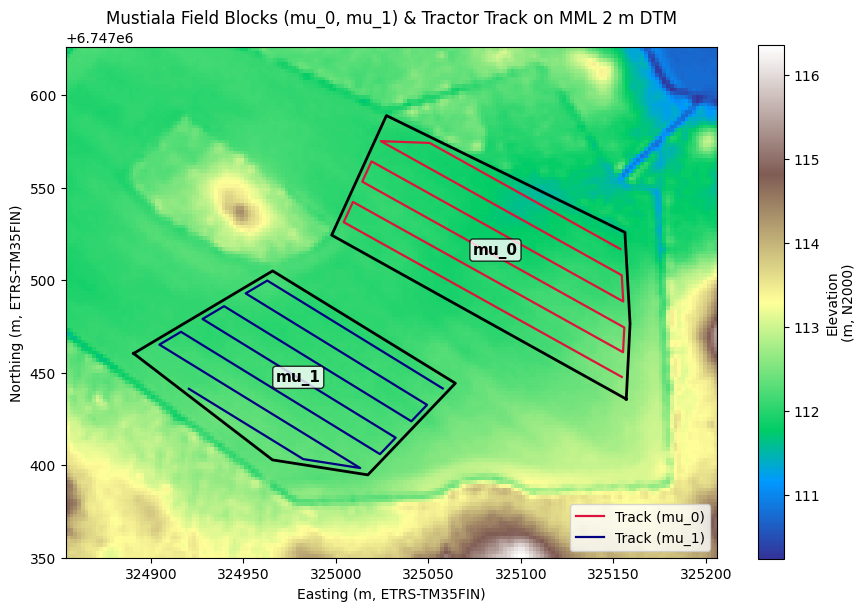

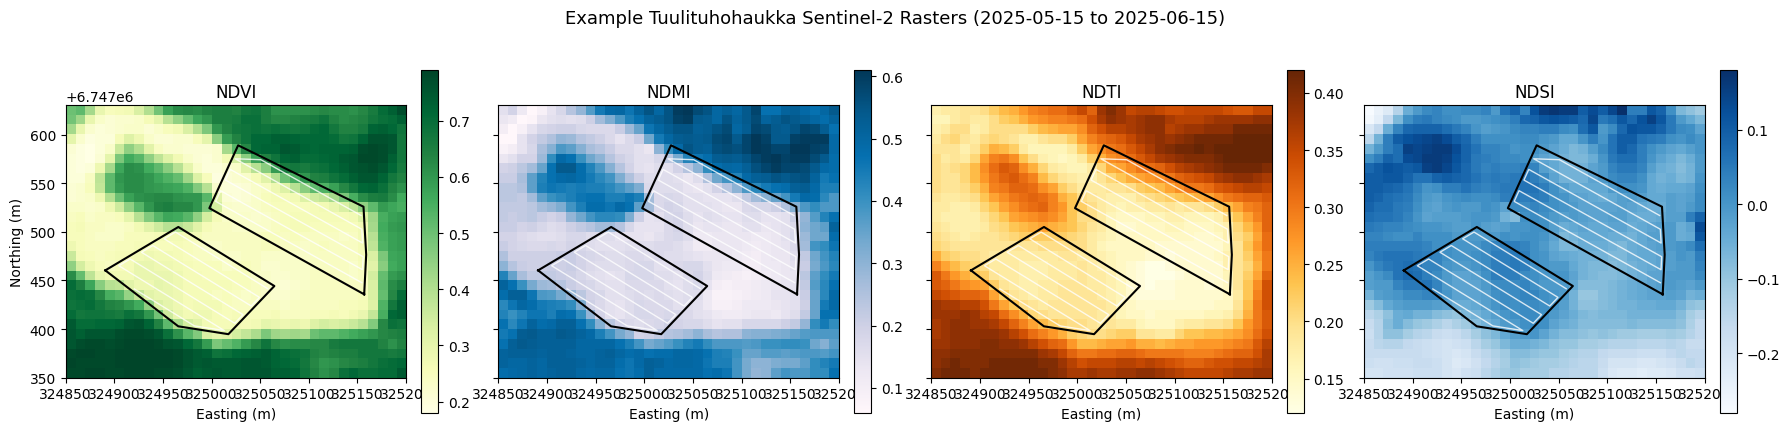

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(dtm_raster, extent=dtm_extent, origin="upper", cmap="terrain")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Elevation\n(m, N2000)")

for fid, poly in polygons_tm35.items():
    px, py = poly.exterior.xy
    ax.plot(px, py, color="black", linewidth=2)
    c = poly.centroid
    ax.text(c.x, c.y, fid, fontsize=11, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))

day1 = df_tracks[df_tracks["work_day"] == "2025-06-15"]
for fid, color in [("mu_0", "crimson"), ("mu_1", "navy")]:
    sub = day1[day1["field_id"] == fid]
    ax.plot(sub["x_tm35"], sub["y_tm35"], color=color, linewidth=1.6, label=f"Track ({fid})")

ax.set_title("Mustiala Field Blocks (mu_0, mu_1) & Tractor Track on MML 2 m DTM")
ax.set_xlabel("Easting (m, ETRS-TM35FIN)")
ax.set_ylabel("Northing (m, ETRS-TM35FIN)")
ax.set_aspect("equal")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Example Sentinel-2 index rasters from the 2025-06-01 to 2025-06-30 period
example_month = "2025-06"
example_period = selected_periods[example_month]
fig, axes = plt.subplots(1, len(INDEX_BANDS), figsize=(18, 4.5), sharex=True, sharey=True)
fig.suptitle(
    f"Example Tuulituhohaukka Sentinel-2 Rasters ({example_period['start'].date()} to {example_period['end'].date()})",
    fontsize=13,
)
cmaps = {"ndvi": "YlGn", "ndmi": "PuBu", "ndti": "YlOrBr", "ndsi": "Blues"}

for ax, band in zip(axes, INDEX_BANDS):
    r_data, r_ext = s2_rasters[example_month][band]
    im = ax.imshow(r_data, extent=r_ext, origin="upper", cmap=cmaps[band])
    for fid, poly in polygons_tm35.items():
        px, py = poly.exterior.xy
        ax.plot(px, py, color="black", linewidth=1.5)
    for fid in ["mu_0", "mu_1"]:
        sub = day1[day1["field_id"] == fid]
        ax.plot(sub["x_tm35"], sub["y_tm35"], color="white", linewidth=1.0, alpha=0.8)
    ax.set_title(band.upper())
    ax.set_xlabel("Easting (m)")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[0].set_ylabel("Northing (m)")
plt.tight_layout()
plt.show()

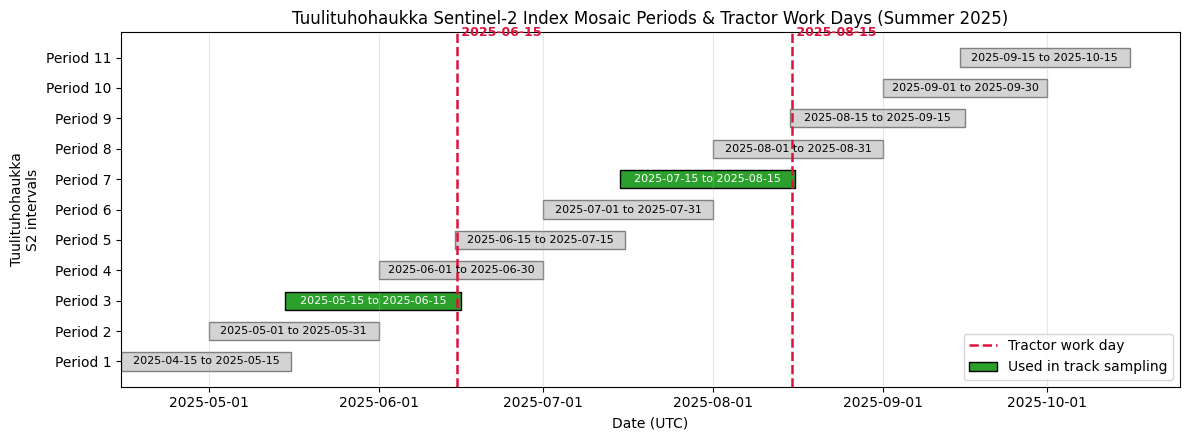

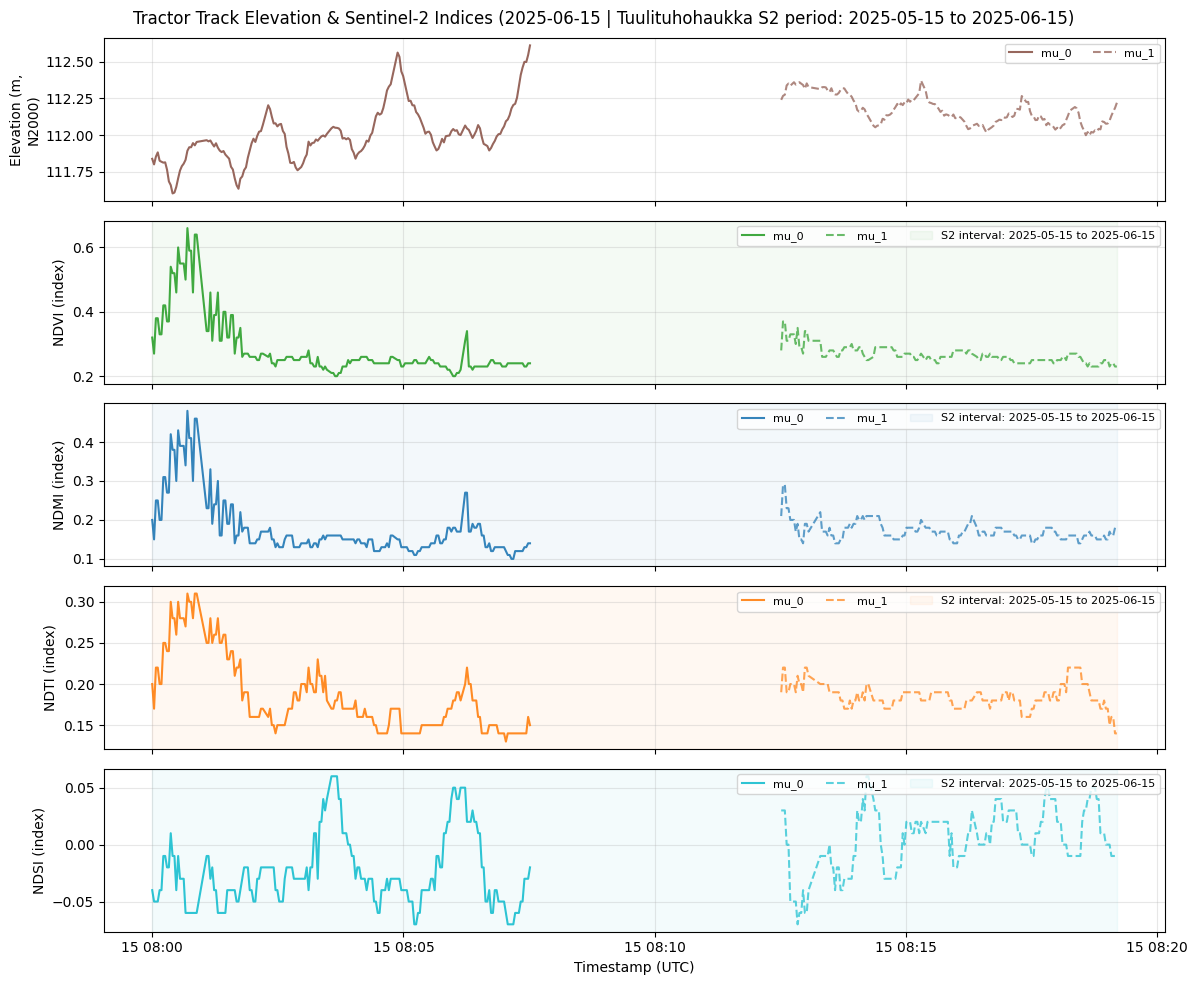

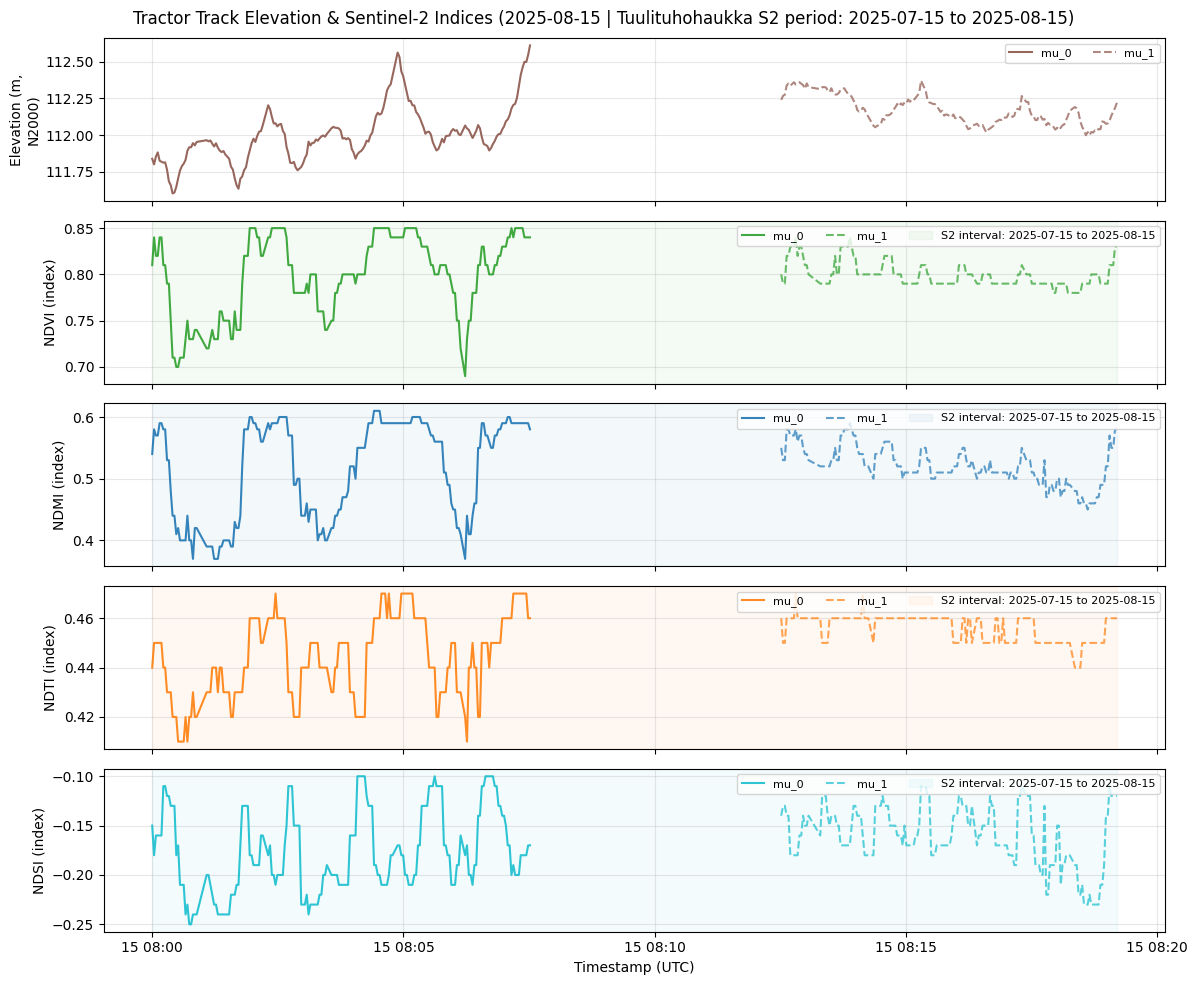

In [21]:
import matplotlib.dates as mdates

# Summer 2025 Tuulituhohaukka Sentinel-2 mosaic periods/intervals vs. tractor work days
fig, ax = plt.subplots(figsize=(12, 4.5))
selected_ids = {row["id"] for row in selected_periods.values()}

for idx, row in df_s2_periods.iterrows():
    start_num = mdates.date2num(row["start"].to_pydatetime())
    width = mdates.date2num(row["end"].to_pydatetime()) - start_num
    is_used = row["id"] in selected_ids
    ax.barh(
        idx, width, left=start_num, height=0.6,
        color="tab:green" if is_used else "lightgray",
        edgecolor="black" if is_used else "gray",
        label="Used in track sampling" if (is_used and idx == df_s2_periods[df_s2_periods["id"].isin(selected_ids)].index[0]) else "",
    )
    ax.text(
        start_num + width / 2, idx,
        f"{row['start'].strftime('%Y-%m-%d')} to {row['end'].strftime('%Y-%m-%d')}",
        va="center", ha="center", fontsize=8,
        color="white" if is_used else "black",
    )

for i, (work_day, _, day_dt) in enumerate(WORK_DATES):
    ax.axvline(day_dt, color="crimson", linestyle="--", linewidth=1.8,
               label="Tractor work day" if i == 0 else "")
    ax.text(day_dt, len(df_s2_periods) - 0.3, f" {work_day}", color="crimson", fontsize=9, fontweight="bold")

ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.set_yticks(range(len(df_s2_periods)))
ax.set_yticklabels([f"Period {i+1}" for i in range(len(df_s2_periods))])
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Tuulituhohaukka\nS2 intervals")
ax.set_title("Tuulituhohaukka Sentinel-2 Index Mosaic Periods & Tractor Work Days (Summer 2025)")
ax.legend(loc="lower right")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

PLOT_SERIES = [
    ("elevation_m", "Elevation (m, N2000)", "tab:brown"),
    ("ndvi", "NDVI (index)", "tab:green"),
    ("ndmi", "NDMI (index)", "tab:blue"),
    ("ndti", "NDTI (index)", "tab:orange"),
    ("ndsi", "NDSI (index)", "tab:cyan"),
]

for work_day, stac_month, _ in WORK_DATES:
    df_day = df_tracks[df_tracks["work_day"] == work_day].set_index("timestamp_utc")
    p_row = selected_periods[stac_month]
    p_label = f"{p_row['start'].strftime('%Y-%m-%d')} to {p_row['end'].strftime('%Y-%m-%d')}"

    fig, axes = plt.subplots(len(PLOT_SERIES), 1, figsize=(12, 10), sharex=True)
    fig.suptitle(
        f"Tractor Track Elevation & Sentinel-2 Indices ({work_day} | Tuulituhohaukka S2 period: {p_label})",
        fontsize=12,
    )

    for ax, (col, label, color) in zip(axes, PLOT_SERIES):
        for fid, style in [("mu_0", "-"), ("mu_1", "--")]:
            sub = df_day[df_day["field_id"] == fid][col]
            ax.plot(sub.index, sub.values, linestyle=style, color=color,
                    alpha=0.9 if fid == "mu_0" else 0.7, label=fid)
        if col in INDEX_BANDS:
            ax.axvspan(df_day.index.min(), df_day.index.max(), color=color, alpha=0.05,
                       label=f"S2 interval: {p_label}")
        ax.set_ylabel(textwrap.fill(label, width=14))
        ax.legend(loc="upper right", ncol=3, fontsize=8)
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Timestamp (UTC)")
    plt.tight_layout()
    plt.show()